## MINI PROJECT

Customer Segmentation for Marketing

In [1]:
import numpy as np

np.random.seed(25)
n_customers = 300

annual_spend = np.concatenate([
    np.random.normal(20000, 5000, 100),   # budget shoppers
    np.random.normal(60000, 8000, 100),   # mid-range
    np.random.normal(120000, 15000, 100)  # premium
])
visit_frequency = np.concatenate([
    np.random.normal(5, 2, 100),
    np.random.normal(15, 3, 100),
    np.random.normal(8, 2, 100)
])

X = np.column_stack([annual_spend, visit_frequency])
np.random.shuffle(X)

- Apply scaling (StandardScaler)
- Use both the Elbow Method and the Silhouette Score to find the best K
- Run the final clustering with the best K and draw a scatter plot (annual_spend vs visit_frequency, coloured by cluster)
- Interpret each cluster centroid in business terms (e.g. "Cluster 0 = high spend, low frequency = premium occasional shoppers")
- Compare n_init=1 vs n_init=10: are the results consistently the same?

In [2]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_scaled = scaler.fit_transform(X)

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(x_scaled)
    labels = kmeans.labels_
    silhouette_avg = silhouette_score(x_scaled, labels)
    print(f"For n_clusters = {k}, the average silhouette score is: {silhouette_avg:.4f}, WCSS: {kmeans.inertia_:.4f}")

For n_clusters = 2, the average silhouette score is: 0.4705, WCSS: 347.8286
For n_clusters = 3, the average silhouette score is: 0.6830, WCSS: 88.4355
For n_clusters = 4, the average silhouette score is: 0.6016, WCSS: 64.1534
For n_clusters = 5, the average silhouette score is: 0.5167, WCSS: 55.3917
For n_clusters = 6, the average silhouette score is: 0.4770, WCSS: 48.0651
For n_clusters = 7, the average silhouette score is: 0.4651, WCSS: 42.9287
For n_clusters = 8, the average silhouette score is: 0.3904, WCSS: 33.8604
For n_clusters = 9, the average silhouette score is: 0.4051, WCSS: 29.7057
For n_clusters = 10, the average silhouette score is: 0.3981, WCSS: 27.2717


In [4]:
best_k = 3

for init in range(1, 11):
    kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=init)
    kmeans.fit(x_scaled)
    labels = kmeans.labels_
    silhouette_avg = silhouette_score(x_scaled, labels)
    print(f"For init = {init}, the average silhouette score is: {silhouette_avg:.4f}, WCSS: {kmeans.inertia_:.4f}")

For init = 1, the average silhouette score is: 0.6830, WCSS: 88.4355
For init = 2, the average silhouette score is: 0.6830, WCSS: 88.4355
For init = 3, the average silhouette score is: 0.6830, WCSS: 88.4355
For init = 4, the average silhouette score is: 0.6830, WCSS: 88.4355
For init = 5, the average silhouette score is: 0.6830, WCSS: 88.4355
For init = 6, the average silhouette score is: 0.6830, WCSS: 88.4355
For init = 7, the average silhouette score is: 0.6830, WCSS: 88.4355
For init = 8, the average silhouette score is: 0.6830, WCSS: 88.4355
For init = 9, the average silhouette score is: 0.6830, WCSS: 88.4355
For init = 10, the average silhouette score is: 0.6830, WCSS: 88.4355


Yes here the results are same

In [5]:
best_k = 3

kmeans = KMeans(n_clusters=best_k, random_state=42)
kmeans.fit(x_scaled)
labels = kmeans.labels_
print(kmeans.cluster_centers_)

[[ 1.25139294 -0.29074476]
 [-1.04317571 -0.85458455]
 [-0.17933231  1.2669851 ]]


In [6]:
cluster_names = {
    0: "Premium Occasional Shoppers",  
    1: "Bargain Hunters",
    2: "VIP Loyalists"
}

text_labels = [cluster_names[i] for i in labels]

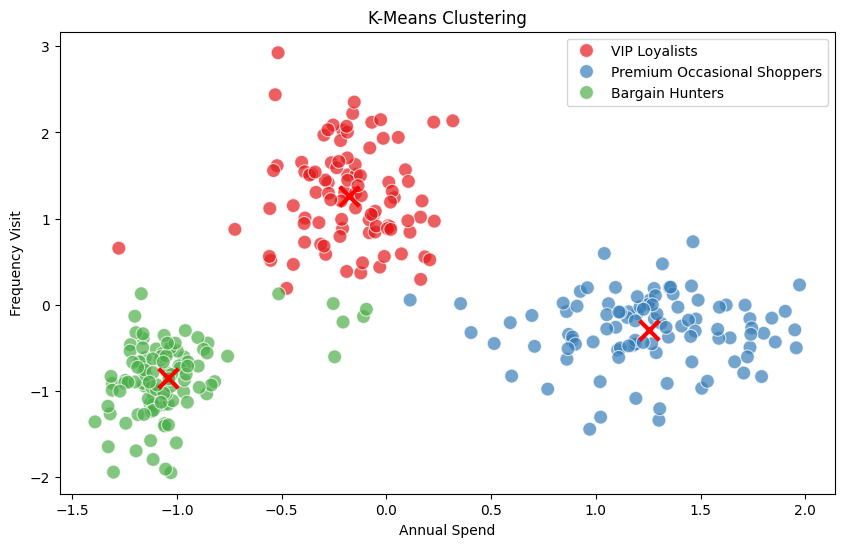

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.scatterplot(x=x_scaled[:, 0], y=x_scaled[:, 1], hue=text_labels, palette='Set1', s=100, alpha=0.7)
sns.scatterplot(x=kmeans.cluster_centers_[:, 0], y=kmeans.cluster_centers_[:, 1], c='red', marker='x', s=200, linewidths=3)
plt.title("K-Means Clustering")
plt.xlabel("Annual Spend")
plt.ylabel("Frequency Visit")
plt.show()

### GMM - Guasian Mixture Models

In [10]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3, random_state=42)  # 'n_components' is the equivalent of K in K-Means
gmm.fit(x_scaled)

labels = gmm.predict(x_scaled)           # hard cluster labels (if needed)
probabilities = gmm.predict_proba(x_scaled)  # SOFT probabilities: a unique feature of GMM

print(probabilities[:5])  # print the probabilities for the first 5 customers

[[9.36611516e-06 3.33947660e-24 9.99990634e-01]
 [1.00000000e+00 1.68630604e-85 1.88144997e-13]
 [9.99997719e-01 4.79138543e-55 2.28089881e-06]
 [1.61397440e-10 9.99999184e-01 8.15907198e-07]
 [1.00000000e+00 1.11502633e-74 8.39483208e-11]]
